In [1]:
from google.colab import drive
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
drive.mount('/content/drive')
df = pd.read_csv('/content/drive/MyDrive/financial_companies.csv')
import warnings
warnings.filterwarnings('ignore')

Mounted at /content/drive


In [2]:
standard_columns = df.columns.str.strip().str.lower()
new_columns = dict(zip(df.columns, standard_columns))
df.rename(columns=new_columns, inplace=True)

# Project: Analysis of Company Financial Indicators with Statistical Hypothesis Tests

Analyze the financial indicators of 100 companies over the past year. The objective is to investigate relationships among company financial indicators and test several economic hypotheses using statistical tests.

## Data description

- `Ownership_Type` — ownership type (categorical variable): `Private` — privately owned; `Public` — publicly traded/listed.
- `Revenue_Mln` — revenue over the past year, in millions of RUB.
- `EBITDA_Mln` — EBITDA over the past year, in millions of RUB (earnings before interest, taxes, depreciation, and amortization).
- `Debt_Ratio` — debt leverage ratio (debt-to-equity ratio).
- `ROE_Percent` — return on equity, in percent.
- `Debt_Ratio_Prev` — debt leverage ratio in the previous year.

## I. Getting familiar with the data


In [3]:
# Display the first five rows of the dataset.
print(df.head(5))
# Determine the dataset dimensions (rows and columns).
print(df.shape)
# List all column names.
print(df.columns)
# Check the data type of each variable.
print(df.info())
# Check for missing values (NaN) in each column.
print(df.isnull().sum())
# Review descriptive statistics: mean, median, standard deviation, minimum, maximum, and quartiles (25%, 75%).
df.describe()
# Analyze the distribution of the categorical variable Ownership_Type:
private = df[(df['ownership_type']=='Private')] # private is a Series
public = df[(df['ownership_type']=='Public')]
# Count observations in each ownership category.
print('Number of private companies',len(private))
print('Number of public companies',len(public))

  ownership_type  revenue_mln  ebitda_mln  debt_ratio  roe_percent  \
0        Private   513.057060  128.589312    1.599530     4.820723   
1         Public   455.148897  150.125576    1.199892     5.950894   
2         Public   513.764116  121.824608    1.534901     9.290200   
3        Private   201.864663  118.470395    1.307343     2.116360   
4        Private   467.049217  132.403988    1.556759     0.026765   

   debt_ratio_prev  
0         1.776750  
1         1.027347  
2         1.521350  
3         1.246869  
4         1.914181  
(100, 6)
Index(['ownership_type', 'revenue_mln', 'ebitda_mln', 'debt_ratio',
       'roe_percent', 'debt_ratio_prev'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ownership_type   100 non-null    object 
 1   revenue_mln      100 non-null    float64
 2   ebitda_mln       100

## II. Analyzing relationships and data distributions

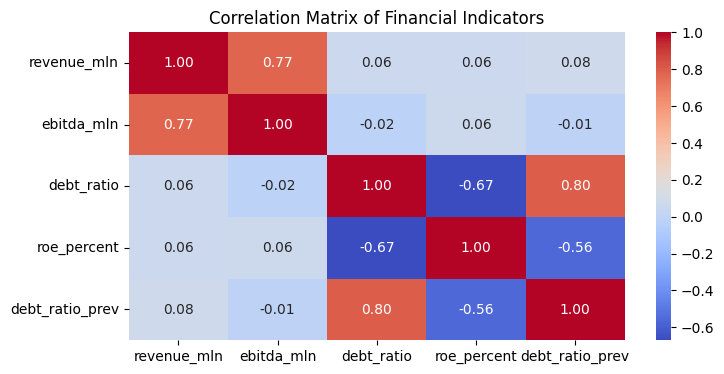

In [4]:
cor = df.corr(numeric_only=True)
plt.figure(figsize=(8,4))
sns.heatmap(cor,cmap= 'coolwarm',fmt='.2f',annot = True) # annot displays the coefficient values on the heatmap.
plt.title('Correlation Matrix of Financial Indicators')
plt.show()

# r(revenue and EBITDA) = 0.77 indicates a strong positive correlation: higher revenue tends to be associated with higher operating earnings. Revenue, EBITDA, and the remaining variables show little correlation.
# r(ROE and debt) = -0.67 suggests that a higher debt burden is associated with lower return on equity.

## III. Pairplot: visualizing relationships among multiple pairs of variables

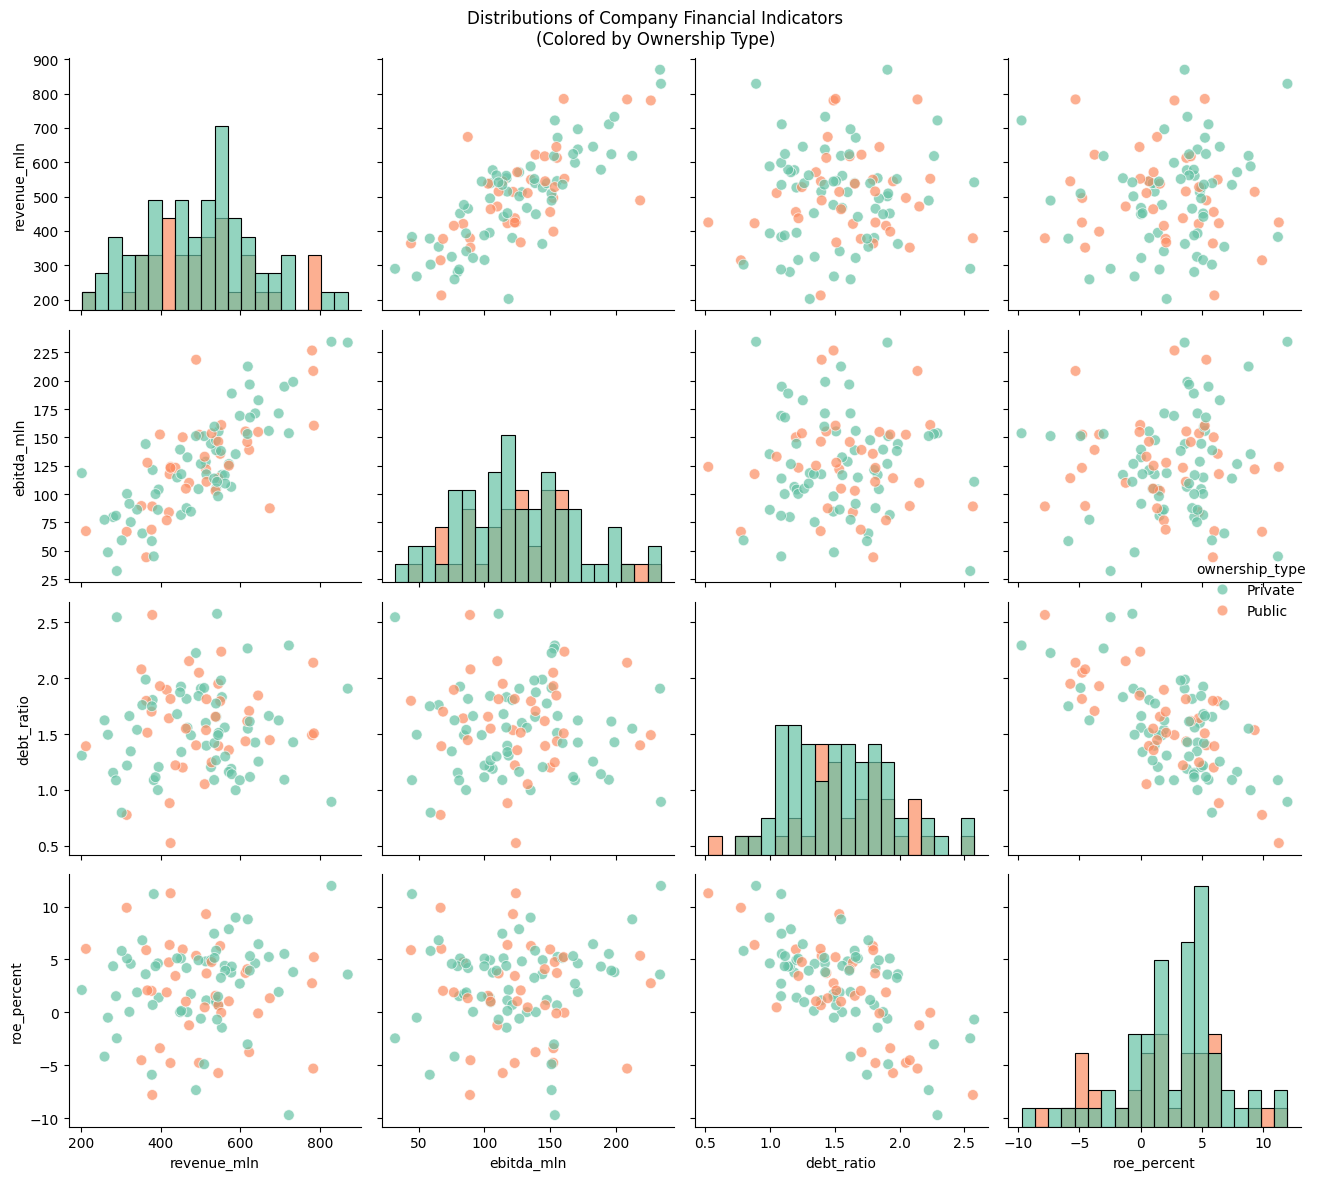

In [5]:
data_pair= df[['revenue_mln', 'ebitda_mln', 'debt_ratio', 'roe_percent', 'ownership_type']]
pairplot = sns.pairplot(
    data=data_pair,
    hue='ownership_type',           # Color points by ownership type
    palette='Set2',
    kind='scatter',
    diag_kind='hist',               # Show histograms on the diagonal
    plot_kws={'alpha': 0.7, 's': 60},
    diag_kws={'bins': 20, 'alpha': 0.7},
    height=3,
)
plt.suptitle('Distributions of Company Financial Indicators\n(Colored by Ownership Type)')
plt.tight_layout()
plt.show()

## IV. Statistical hypothesis testing

For each test, calculate the test statistic and p-value, draw a conclusion at significance level α = 0.05, and interpret the result in an economic context.

### Hypothesis 1
The average company revenue exceeds 480 million RUB.  
H₀: μ ≤ 480. H₁: μ > 480.  
**Economic interpretation:** If the hypothesis is supported, companies in the sample may be performing above the industry average. This could be related to favorable market conditions or a high concentration of successful businesses in the sample.

### Hypothesis 2
The average return on equity (ROE) is not above 15%.  
H₀: μ ≥ 15. H₁: μ < 15.  
**Economic interpretation:** If ROE is significantly below 15%, this may indicate inefficient equity management, a high debt burden eroding profits, or unfavorable macroeconomic conditions.

### Hypothesis 3
Public companies have higher EBITDA than private companies.  
H₀: μ₁ ≤ μ₂ (public-company EBITDA ≤ private-company EBITDA).  
H₁: μ₁ > μ₂ (public-company EBITDA > private-company EBITDA).  
**Economic interpretation:** Higher EBITDA at public companies may be explained by cheaper access to public capital markets, economies of scale, or more efficient management processes.

### Hypothesis 4
Private companies have a lower debt leverage ratio than public companies.  
H₀: μ₁ ≥ μ₂ (private-company debt ratio ≥ public-company debt ratio).  
H₁: μ₁ < μ₂ (private-company debt ratio < public-company debt ratio).  
**Economic interpretation:** A lower debt ratio among private companies may reflect owners' caution about borrowing, more limited access to credit without public-company status, or a desire to retain full control of the business.

In [6]:
from statsmodels.stats.proportion import proportions_ztest
import pandas as pd
from scipy import stats

alpha = 0.05

# H1: Revenue > 480
t1, p1 = stats.ttest_1samp(df['revenue_mln'], popmean=480, alternative = 'greater')
print("H1: Revenue > 480")
print("t =", round(t1, 4), "p =", round(p1, 4))
if p1 < 0.05: print("Reject H0: revenue > 480")
else: print("Insufficient evidence to reject H0; mean revenue is less than or equal to 480")

# H1: ROE < 15
t2, p2 = stats.ttest_1samp(df['roe_percent'], popmean = 15, alternative= 'less' )
print("H1: ROE < 15")
print("t =", round(t2, 4), "p =", round(p2, 4))
if p2 < 0.05: print("Reject H0: ROE is below 15%")
else: print("Insufficient evidence to reject H0; mean ROE is greater than or equal to 15%")

# H1: Public-company EBITDA > private-company EBITDA
pub = df[df['ownership_type'] == 'Public']['ebitda_mln']
pri = df[df['ownership_type'] == 'Private']['ebitda_mln']
t3, p3 = stats.ttest_ind(pub, pri, equal_var=True, alternative = 'greater') # The order of the groups matters because it determines the alternative hypothesis.
print("H3: Public-company EBITDA > private-company EBITDA")
print("t =", round(t3, 4), "p =", round(p3,4))
if p3 < 0.05: print("Reject H0: public-company EBITDA is greater than private-company EBITDA")
else:  print("Insufficient evidence to reject H0; public-company EBITDA is less than or equal to private-company EBITDA")

# H1: Private-company debt ratio < public-company debt ratio (mu1 < mu2)
pri_d = df[df['ownership_type'] == 'Private']['debt_ratio']
pub_d = df[df['ownership_type'] == 'Public']['debt_ratio']
t4, p4 = stats.ttest_ind(pri_d,pub_d , equal_var=True, alternative= 'less')
print("H4: Private-company debt ratio < public-company debt ratio")
print("t =", round(t4, 4), "p =", round(p4,4))
if p4 < 0.05:  print("Reject H0: the private-company debt ratio is lower than the public-company debt ratio")
else:  print("Insufficient evidence to reject H0; the private-company debt ratio is greater than or equal to the public-company debt ratio")

H1: Revenue > 480
t = 1.4487 p = 0.0753
Insufficient evidence to reject H0; mean revenue is less than or equal to 480
H1: ROE < 15
t = -29.4842 p = 0.0
Reject H0: ROE is below 15%
H3: Public-company EBITDA > private-company EBITDA
t = 0.069 p = 0.4726
Insufficient evidence to reject H0; public-company EBITDA is less than or equal to private-company EBITDA
H4: Private-company debt ratio < public-company debt ratio
t = -0.8745 p = 0.192
Insufficient evidence to reject H0; the private-company debt ratio is greater than or equal to the public-company debt ratio


### Hypothesis 5
Companies' debt leverage ratios have changed significantly over the past year.  
H₀: μ_diff = 0 (no change). H₁: μ_diff ≠ 0 (a change occurred).  
**Economic interpretation:** If H₀ is rejected and the mean change is positive, companies are increasing leverage, possibly to finance growth. If the mean change is negative, companies are reducing debt. If the change is not statistically significant, the capital structure may be stable.

### Hypothesis 6
The proportion of companies with a high debt leverage ratio (`Debt_Ratio` > 2.0) is 30%.  
H₀: p = 0.3 (the proportion is 30%). H₁: p ≠ 0.3.  
**Economic interpretation:** This test helps assess financial risk in the company sample.

- If H₀ is rejected and the actual proportion is above 30%, high borrowing may be common. Companies may be actively using debt to grow, potentially increasing systemic risk if interest rates rise.
- If H₀ is rejected and the actual proportion is below 30%, companies may be following more conservative financial policies, or access to credit may be limited. Default risk may be lower, although business growth could also be slower.
- If there is insufficient evidence to reject H₀ (p ≥ 0.05), the debt-ratio distribution is consistent with the expected 30% benchmark, suggesting a balance between risk and growth.

### Hypothesis 7
The ROE distributions of private and public companies are the same.  
H₀: The ROE distributions of private and public companies do not differ (their medians are equal).  
H₁: The ROE distributions differ (their medians are not equal).  
**Method:** Split the sample by `Ownership_Type` and perform a non-parametric Mann–Whitney test.

In [7]:
# HYPOTHESIS 5: Test whether Debt_Ratio changed from the previous year using a paired t-test.
df['debt_diff'] = df['debt_ratio'] - df['debt_ratio_prev']
t5,p5 = stats.ttest_rel(df['debt_ratio'],df['debt_ratio_prev'],alternative = 'two-sided') # The order of the two groups does not matter for a two-sided test.
print('t =',round(t5,4),'p =',round(p5,4))
if p5 < 0.05:
    print("Reject H0: a statistically significant change occurred")
    if df['debt_diff'].mean() > 0: # Check whether the mean of debt_diff is positive.
        print("Companies are increasing leverage → Debt may be used to finance growth and expansion")
    else:  print("Companies are reducing leverage → They may be repaying debt and reducing financial risk")
else: print("Insufficient evidence to reject H0; companies have maintained a debt leverage ratio similar to the previous year, with no significant change in debt policy")
# Alternative method: perform a one-sample test on the difference between the two years.
df['debt_diff'] = df['debt_ratio'] - df['debt_ratio_prev']
t5, p5 = stats.ttest_1samp(df['debt_diff'], 0,alternative = "two-sided")
print("t =", round(t5, 4), "p =", round(p5, 4))

# HYPOTHESIS 6: Test whether the proportion with Debt_Ratio > 2.0 differs from 30%.
so_quan_sat_dat = (df['debt_ratio']> 2.0).sum()
tong_so_quan_sat = len(df)
ty_le = so_quan_sat_dat/tong_so_quan_sat
z6,p6 = proportions_ztest(so_quan_sat_dat, tong_so_quan_sat,value = 0.3) # proportions_ztest takes counts, not the individual observations.
print("z6 =", round(z6, 4), "p6 =", round(p6, 4))
if p6 < 0.05:
    print("Reject H0: the proportion of companies with a debt ratio above 2 differs from 30% ")
    if ty_le > 0.3:
        print(" The actual proportion is above 30%, indicating more companies have high debt")
    else:print("The actual proportion is below 30%")
else: print("Insufficient evidence to reject H0; the proportion of companies with a debt ratio above 2 may be 30%")

# HYPOTHESIS 7: Compare public vs. private ROE using the Mann–Whitney test.
roe_public = df[df['ownership_type'] == 'Public']['roe_percent']
roe_private = df[df['ownership_type'] == 'Private']['roe_percent']
u7, p7 = stats.mannwhitneyu(roe_public, roe_private, alternative='two-sided')
print("U =", round(u7, 4), "p =", round(p7, 4))
if p7 < 0.05: print("Reject H0: the ROE distributions of the two company types differ")
else: print("Insufficient evidence to reject H0; the ROE distributions of the two company types may be similar")

t = -4.1229 p = 0.0001
Reject H0: a statistically significant change occurred
Companies are reducing leverage → They may be repaying debt and reducing financial risk
t = -4.1229 p = 0.0001
z6 = -6.0724 p6 = 0.0
Reject H0: the proportion of companies with a debt ratio above 2 differs from 30% 
The actual proportion is below 30%
U = 1047.0 p = 0.3995
Insufficient evidence to reject H0; the ROE distributions of the two company types may be similar


# Overall Project Conclusion

## Main steps of the project

- **One-sample tests:** Evaluate the sample companies' mean revenue and mean ROE.
- **Independent two-sample tests:** Compare EBITDA (H3) and debt leverage ratio (H4) between public and private companies.
- **Paired test:** Evaluate the year-over-year change in debt leverage ratio.
- **Proportion test:** Estimate the proportion of companies with high debt ratios in the sample.
- **Mann–Whitney non-parametric test:** Compare the ROE distributions of the two company groups.

## Were the main economic hypotheses supported?

**Hypothesis 1 (mean revenue > 480 million RUB):** The test did not provide sufficient evidence to reject H₀ (p > 0.05). The sample companies' mean revenue is not statistically significantly above 480 million RUB; their revenue is broadly consistent with the benchmark used.

**Hypothesis 2 (mean ROE < 15%):** The test rejects H₀ (p < 0.05). Mean ROE is statistically significantly below 15%. This may reflect limited effectiveness in managing equity, potentially due to a high debt burden or unfavorable macroeconomic conditions.

**Hypothesis 3 (public-company EBITDA > private-company EBITDA):** There is insufficient evidence to reject H₀ (p > 0.05). Mean EBITDA does not differ significantly between the two groups. Any public-company advantage in access to capital is not clearly reflected in EBITDA.

**Hypothesis 4 (private-company debt ratio < public-company debt ratio):** There is insufficient evidence to reject H₀ (p > 0.05). No statistically significant difference in debt leverage ratio was found between the two groups.

**Hypothesis 5 (debt ratio changed year over year):** There is insufficient evidence to reject H₀ (p > 0.05). The companies' debt leverage ratios did not change significantly from the previous year, suggesting a relatively stable capital structure.

**Hypothesis 6 (the proportion of companies with a debt ratio > 2.0 is 30%):** There is insufficient evidence to reject H₀ (p > 0.05). The proportion of companies with high debt ratios is not statistically significantly different from the expected 30% benchmark.

**Hypothesis 7 (ROE distributions differ between the two company groups):** The Mann–Whitney test did not provide sufficient evidence to reject H₀ (p > 0.05). The ROE distributions of private and public companies do not differ significantly.

**Overall conclusion:** Based on the available sample, there is insufficient statistical evidence to establish clear differences between private and public companies in EBITDA, debt ratio, or ROE. Mean revenue is broadly consistent with the selected benchmark, while mean ROE is significantly below the expected 15%, suggesting that companies may need to improve how effectively they use equity. Capital structures appear stable year over year, and the proportion of companies with high debt ratios is consistent with the 30% benchmark.